# TEHI-2026 · Clinical experiment with 5,000 NHANES records

**Goal:** Test Random Forest, XGBoost, LightGBM, and CatBoost on a **real NHANES 5,000-record balanced subset** with a held-out test set and stratified 5-fold cross-validation **inside the training set**.

**Important:** This is a *new NHANES-based experiment*, **not** a recreation of the original lost Pima-based experiment. The prediction target is self-reported physician-diagnosed diabetes status; it is **not** prediction of future diabetic complications. Do not substitute these results for the previously reported 93.4% XGBoost score without revising the manuscript and explaining the changes.

**How to use:** Run cells from top to bottom in Google Colab. When asked, upload `TEHI218_5000_Feasibility_Audit_Package.zip`.

## 1 · Install dependencies

In [3]:
%pip -q install xgboost lightgbm catboost joblib

## 2 · Upload the audit ZIP and load the balanced CSV

In [6]:
from google.colab import files
import io, zipfile, pandas as pd, numpy as np

uploaded = files.upload()
zip_names = [k for k in uploaded if k.lower().endswith('.zip')]
assert zip_names, 'Please upload TEHI218_5000_Feasibility_Audit_Package.zip'
zip_name = zip_names[0]
selected_csv = 'TEHI218_NHANES_CLINICAL_5000_BALANCED.csv'
with zipfile.ZipFile(io.BytesIO(uploaded[zip_name])) as z:
    matches = [nm for nm in z.namelist() if nm.rsplit('/',1)[-1] == selected_csv]
    assert len(matches)==1, f'{selected_csv} missing or ambiguous in ZIP.'
    df = pd.read_csv(z.open(matches[0]))

print('Loaded:', selected_csv, '| shape:', df.shape)
print('Outcome distribution:')
print(df['Outcome'].value_counts().sort_index())
print('Columns:', list(df.columns))
assert len(df)==5000 and set(df.Outcome.dropna().unique())=={0,1}
assert (df.Outcome.value_counts().sort_index().values == [2500,2500]).all()
assert df['participant_id'].is_unique, 'Participant IDs must be unique.'
display(df.head(3))

Saving TEHI218_5000_Feasibility_Audit_Package.zip to TEHI218_5000_Feasibility_Audit_Package.zip
Loaded: TEHI218_NHANES_CLINICAL_5000_BALANCED.csv | shape: (5000, 14)
Outcome distribution:
Outcome
0    2500
1    2500
Name: count, dtype: int64
Columns: ['participant_id', 'cycle', 'cycle_start', 'Age', 'Sex', 'RaceEthnicityCode', 'BMI', 'WaistCm', 'HbA1c', 'FastingGlucose_mg_dL', 'Outcome', 'WTMEC2YR', 'SDMVPSU', 'SDMVSTRA']


,participant_id,cycle,cycle_start,Age,Sex,RaceEthnicityCode,BMI,WaistCm,HbA1c,FastingGlucose_mg_dL,Outcome,WTMEC2YR,SDMVPSU,SDMVSTRA
0,101787.0,2017-2018,2017,30.0,1.0,4.0,34.2,110.4,4.6,87.0,0,21336.954409,2.0,148.0
1,77600.0,2013-2014,2013,58.0,2.0,2.0,41.2,124.9,10.1,159.0,1,15073.244399,2.0,117.0
2,86999.0,2015-2016,2015,76.0,1.0,4.0,27.6,111.7,9.1,NaN,1,13279.208082,2.0,119.0


## 3 · Prepare features and a locked 20% held-out test set

The ID, survey cycle, and survey design variables are **not predictors**. Splitting occurs before imputation, so validation/test values cannot influence training preprocessing.

In [7]:
from sklearn.model_selection import train_test_split

feature_columns = [
    'Age','Sex','RaceEthnicityCode','BMI',
    'WaistCm','HbA1c','FastingGlucose_mg_dL'
]
target_col = 'Outcome'
missing = set(feature_columns+[target_col]) - set(df.columns)
assert not missing, f'Missing required columns: {missing}'
X = df[feature_columns].apply(pd.to_numeric, errors='coerce')
y = df[target_col].astype(int)
ids = df['participant_id']
Xtr, Xte, ytr, yte, idtr, idte = train_test_split(
    X, y, ids, test_size=0.2, stratify=y, random_state=42
)
assert set(idtr).isdisjoint(set(idte)), 'Patient leakage detected.'
print('Train:', len(Xtr),'Test:',len(Xte))
print('Train classes:', ytr.value_counts().to_dict())
print('Test classes:', yte.value_counts().to_dict())
print('Missing fraction, train:')
print(Xtr.isna().mean().round(3).to_string())

Train: 4000 Test: 1000
Train classes: {1: 2000, 0: 2000}
Test classes: {0: 500, 1: 500}
Missing fraction, train:
Age                     0.000
Sex                     0.000
RaceEthnicityCode       0.000
BMI                     0.018
WaistCm                 0.064
HbA1c                   0.000
FastingGlucose_mg_dL    0.530


## 4 · Train-only stratified five-fold evaluation of all four models

In [8]:
from sklearn.model_selection import StratifiedKFold, cross_validate
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.ensemble import RandomForestClassifier
from xgboost import XGBClassifier
from lightgbm import LGBMClassifier
from catboost import CatBoostClassifier

models = {
    'RandomForest': RandomForestClassifier(n_estimators=300,random_state=42,n_jobs=2),
    'XGBoost': XGBClassifier(n_estimators=300,max_depth=3,learning_rate=0.05,
                             tree_method='hist',eval_metric='logloss',random_state=42,n_jobs=2),
    'LightGBM': LGBMClassifier(n_estimators=300,learning_rate=0.05,
                               verbose=-1,random_state=42,n_jobs=2),
    'CatBoost': CatBoostClassifier(iterations=300,learning_rate=0.05,depth=4,
                                  verbose=False,random_seed=42,thread_count=2),
}
cv = StratifiedKFold(n_splits=5,shuffle=True,random_state=42)
scoring = {'accuracy':'accuracy','precision':'precision','recall':'recall',
           'f1':'f1','roc_auc':'roc_auc'}
rows=[]; fold_rows=[]
for name, estimator in models.items():
    pipeline = Pipeline([
        ('imputer',SimpleImputer(strategy='median')),
        ('model',estimator)
    ])
    scores = cross_validate(pipeline,Xtr,ytr,cv=cv,scoring=scoring,n_jobs=1,error_score='raise')
    row = {'Model':name}
    for metric in scoring:
        vals = scores['test_'+metric]
        row[f'CV_{metric}_mean'] = vals.mean()
        row[f'CV_{metric}_sd'] = vals.std(ddof=1)
        for fold,value in enumerate(vals,1):
            fold_rows.append({'Model':name,'Fold':fold,'Metric':metric,'Value':float(value)})
    rows.append(row)
    print(name,'finished | CV AUC:',round(row['CV_roc_auc_mean'],4))

cv_results = pd.DataFrame(rows).sort_values('CV_roc_auc_mean',ascending=False).reset_index(drop=True)
fold_results = pd.DataFrame(fold_rows)
display(cv_results.round(4))

RandomForest finished | CV AUC: 0.9362
XGBoost finished | CV AUC: 0.9392


/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/ut

LightGBM finished | CV AUC: 0.9329
CatBoost finished | CV AUC: 0.9405


,Model,CV_accuracy_mean,CV_accuracy_sd,CV_precision_mean,CV_precision_sd,CV_recall_mean,CV_recall_sd,CV_f1_mean,CV_f1_sd,CV_roc_auc_mean,CV_roc_auc_sd
0,CatBoost,0.8672,0.0115,0.8873,0.0147,0.8415,0.0104,0.8638,0.0115,0.9405,0.0085
1,XGBoost,0.8640,0.0079,0.8874,0.0129,0.8340,0.0045,0.8598,0.0074,0.9392,0.0082
2,RandomForest,0.8625,0.0165,0.8810,0.0215,0.8385,0.0124,0.8592,0.0163,0.9362,0.0100
3,LightGBM,0.8588,0.0083,0.8756,0.0128,0.8365,0.0126,0.8555,0.0085,0.9329,0.0078


## 5 · Fit the train-only CV-selected model and evaluate once on the held-out test set

In [9]:
from sklearn.metrics import (accuracy_score,precision_score,recall_score,f1_score,
                             roc_auc_score, confusion_matrix,classification_report,roc_curve)

best_name = str(cv_results.loc[0,'Model'])
pipe = Pipeline([
    ('imputer',SimpleImputer(strategy='median')),
    ('model',models[best_name])
])
pipe.fit(Xtr,ytr)
pred = pipe.predict(Xte)
probs = pipe.predict_proba(Xte)[:,1]
cm = confusion_matrix(yte,pred,labels=[0,1])
tn, fp, fn, tp = cm.ravel()
metrics = {
    'selected_model':best_name,
    'test_accuracy':accuracy_score(yte,pred),
    'test_precision_positive':precision_score(yte,pred,zero_division=0),
    'test_recall_sensitivity_positive':recall_score(yte,pred,zero_division=0),
    'test_specificity_negative':tn/(tn+fp),
    'test_f1_positive':f1_score(yte,pred,zero_division=0),
    'test_roc_auc':roc_auc_score(yte,probs),
    'TN':int(tn),'FP':int(fp),'FN':int(fn),'TP':int(tp),
    'test_n':len(yte), 'train_n':len(ytr)
}
print('SELECTED MODEL:',best_name)
for k,v in metrics.items(): print(k,':',v)
print('\nClassification report:\n',classification_report(yte,pred,digits=4))
print('Confusion matrix:\n',cm)

SELECTED MODEL: CatBoost
selected_model : CatBoost
test_accuracy : 0.86
test_precision_positive : 0.879746835443038
test_recall_sensitivity_positive : 0.834
test_specificity_negative : 0.886
test_f1_positive : 0.8562628336755647
test_roc_auc : 0.938584
TN : 443
FP : 57
FN : 83
TP : 417
test_n : 1000
train_n : 4000

Classification report:
               precision    recall  f1-score   support

           0     0.8422    0.8860    0.8635       500
           1     0.8797    0.8340    0.8563       500

    accuracy                         0.8600      1000
   macro avg     0.8610    0.8600    0.8599      1000
weighted avg     0.8610    0.8600    0.8599      1000

Confusion matrix:
 [[443  57]
 [ 83 417]]


## 6 · Save confusion matrix, ROC curve and reproducibility files

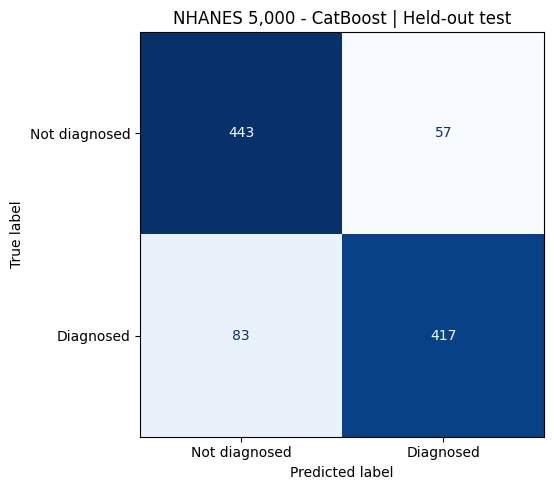

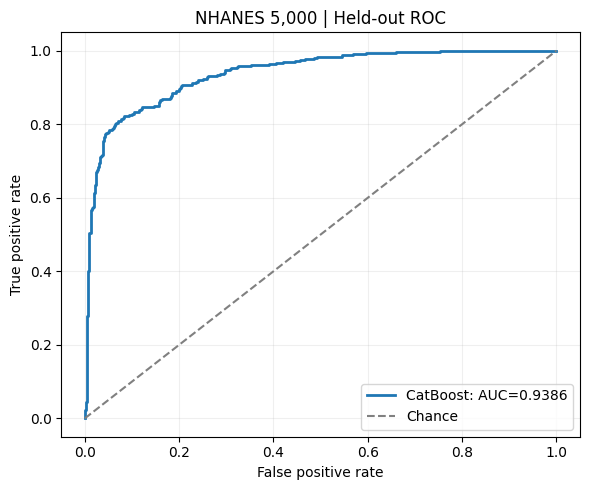

Saved files: ['selected_model_pipeline.joblib', 'train_only_cv_folds.csv', 'roc_curve.png', 'confusion_matrix.png', 'train_only_cv_summary.csv', 'experiment_notes.txt', 'heldout_test_metrics.json', 'heldout_test_predictions.csv']


In [10]:
import matplotlib.pyplot as plt, json, joblib, os, zipfile
from sklearn.metrics import ConfusionMatrixDisplay
out='/content/TEHI218_5000_Experiment_Results'
os.makedirs(out,exist_ok=True)

fig,ax=plt.subplots(figsize=(6,5))
ConfusionMatrixDisplay(cm,display_labels=['Not diagnosed','Diagnosed']).plot(
    ax=ax,cmap='Blues',values_format='d',colorbar=False)
ax.set_title(f'NHANES 5,000 - {best_name} | Held-out test')
fig.tight_layout();fig.savefig(f'{out}/confusion_matrix.png',dpi=300);plt.show();plt.close(fig)

fpr,tpr,_=roc_curve(yte,probs)
fig,ax=plt.subplots(figsize=(6,5))
ax.plot(fpr,tpr,label=f'{best_name}: AUC={metrics["test_roc_auc"]:.4f}',lw=2)
ax.plot([0,1],[0,1],'--',color='gray',label='Chance')
ax.set(xlabel='False positive rate',ylabel='True positive rate',title='NHANES 5,000 | Held-out ROC')
ax.legend();ax.grid(alpha=.2);fig.tight_layout()
fig.savefig(f'{out}/roc_curve.png',dpi=300);plt.show();plt.close(fig)

cv_results.to_csv(f'{out}/train_only_cv_summary.csv',index=False)
fold_results.to_csv(f'{out}/train_only_cv_folds.csv',index=False)
pd.DataFrame({'participant_id':idte.to_numpy(),'true':yte.to_numpy(),
              'predicted':pred,'probability_positive':probs}).to_csv(
    f'{out}/heldout_test_predictions.csv',index=False)
with open(f'{out}/heldout_test_metrics.json','w') as f:
    json.dump(metrics,f,indent=2)
with open(f'{out}/experiment_notes.txt','w') as f:
    f.write('Dataset: CDC NHANES 2007-2018 derived, balanced subset of 5,000.\n')
    f.write('Target: self-reported physician-diagnosed diabetes status (NOT future complications).\n')
    f.write('Subset: 2,500 positive and 2,500 negative.\n')
    f.write('Predictors: '+', '.join(feature_columns)+'\n')
    f.write('Excluded: participant_id, cycle and survey design columns.\n')
    f.write('80/20 stratified holdout; train-only 5-fold stratified CV; median imputation in fold pipeline.\n')
    f.write('CV model selection by ROC-AUC, one final evaluation on 20% holdout.\n')
    f.write('This is a new experiment, not a reproduction of the original Pima-based results.\n')
    f.write('Balanced sample metrics do not estimate general population performance.\n')
joblib.dump(pipe,f'{out}/selected_model_pipeline.joblib')
print('Saved files:',os.listdir(out))

## 7 · Download the complete results ZIP

In [11]:
from google.colab import files
zip_out='/content/TEHI218_5000_Experiment_Results.zip'
with zipfile.ZipFile(zip_out,'w',zipfile.ZIP_DEFLATED) as z:
    for fname in os.listdir(out):
        z.write(os.path.join(out,fname),arcname=fname)
files.download(zip_out)

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

## Research caveats (read before including results in the paper)

- This subset was balanced **by selection**, not observed population prevalence. Report the actual class distribution and limitations clearly.
- HbA1c and fasting glucose may correlate strongly with current diabetes status. Check label origin and data leakage; do not describe these as *future complication-risk* results.
- These cross-validation scores describe NHANES data only; external validation, data-source shifts, survey weighting, and clinical evaluation remain outstanding.
- Only the top CV-selected model is evaluated on held-out data here. Do not claim equivalent held-out metrics for all models.
- Retinal/Grad-CAM evaluation requires separate labeled fundus images and trained imaging models.